# MODELING CATBOOST

<h3>Cell 0 - Import & Install CatBoost</h3>
<p>
Pada cell ini, kami memastikan library <code>catboost</code> tersedia. Jika belum terpasang, cell melakukan instalasi melalui pip, lalu menampilkan versi CatBoost yang digunakan.
</p>
<p>
Langkah ini penting untuk reproducibility notebook, karena CatBoost bukan dependency default pada banyak environment Python.
</p>

In [3]:
# Cell 0 — Import + install CatBoost
import sys

try:
    import catboost
    print("CatBoost version:", catboost.__version__)
except Exception as e:
    print("CatBoost not found. Installing...")
    !{sys.executable} -m pip install -q catboost
    import catboost
    print("CatBoost version:", catboost.__version__)

CatBoost version: 1.2.8


<h3>Cell 1 - Load Data, Parse Tanggal, dan Filter Data Berlabel</h3>
<p>
Cell ini memuat file <code>sparc_labeled.csv</code> (hasil labeling), lalu melakukan parsing kolom <code>tgl mohon</code> menjadi datetime agar bisa dipakai untuk split berbasis waktu.
</p>
<p>
Selanjutnya, kami hanya mengambil data yang memiliki target <code>label_repeat_next</code> (drop NaN). Baris dengan label NaN umumnya terjadi karena <code>tgl mohon</code> kosong sehingga target time-aware tidak dapat dibentuk. Hasil akhirnya adalah dataset modeling dengan ukuran yang konsisten dan target bertipe integer.
</p>

In [4]:
# Cell 1 — Load data + filter berlabel + parse tgl mohon
import os
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, f1_score

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

labeled_path = os.path.join(os.getcwd(), "sparc_labeled.csv")
df = pd.read_csv(labeled_path, low_memory=False)
print("Shape:", df.shape)

df["tgl mohon"] = pd.to_datetime(df["tgl mohon"], errors="coerce")
df_model = df[df["label_repeat_next"].notna()].copy()
df_model["label_repeat_next"] = df_model["label_repeat_next"].astype(int)

print("Rows for modeling:", df_model.shape[0])
print("Repeat-next rate:", round(df_model["label_repeat_next"].mean() * 100, 2), "%")
print("tgl mohon NaT in df_model:", int(df_model["tgl mohon"].isna().sum()))

Shape: (319978, 34)
Rows for modeling: 222314
Repeat-next rate: 12.5 %
tgl mohon NaT in df_model: 0


<h3>Cell 2 - Time-based Train/Test Split</h3>
<p>
Di cell ini, data disortir berdasarkan <code>tgl mohon</code> dan dipisah menjadi train dan test secara time-based: 80% tanggal awal untuk train dan 20% tanggal akhir untuk test.
</p>
<p>
Pendekatan ini menjaga evaluasi tetap realistis (training dari histori dan pengujian pada periode masa depan) dan mengurangi risiko leakage. Pada label “repeat-next”, perbedaan base rate antara train dan test dapat muncul karena right-censoring pada akhir periode data (transaksi di akhir timeline memiliki peluang lebih kecil untuk memiliki transaksi berikutnya di dalam data yang tersedia).
</p>

In [5]:
# Cell 2 — Time-based split (80% awal train, 20% akhir test)
df_model = df_model.sort_values("tgl mohon").reset_index(drop=True)
split_idx = int(len(df_model) * 0.8)

train_df = df_model.iloc[:split_idx].copy()
test_df  = df_model.iloc[split_idx:].copy()

y_train = train_df["label_repeat_next"].values
y_test  = test_df["label_repeat_next"].values

print("Train period:", train_df["tgl mohon"].min(), "->", train_df["tgl mohon"].max(), "| n:", train_df.shape[0])
print("Test period :", test_df["tgl mohon"].min(),  "->", test_df["tgl mohon"].max(),  "| n:", test_df.shape[0])
print("Train repeat rate:", round(y_train.mean() * 100, 2), "%")
print("Test repeat rate :", round(y_test.mean() * 100, 2), "%")

Train period: 2019-01-02 00:00:00 -> 2025-01-11 00:00:00 | n: 177851
Test period : 2025-01-11 00:00:00 -> 2025-12-31 00:00:00 | n: 44463
Train repeat rate: 14.71 %
Test repeat rate : 3.69 %


<h3>Cell 3 - Feature Selection (Drop Leakage/ID/Datetime Mentah)</h3>
<p>
Pada versi terbaru pipeline, fitur turunan waktu dari <code>tgl mohon</code>
(<code>mohon_year</code>, <code>mohon_month</code>, <code>mohon_dow</code>, dan <code>mohon_quarter</code>)
sudah dibuat lebih awal pada tahap <b>Preprocessing &amp; Feature Engineering</b> sebelum data disimpan ke CSV.
Karena itu, pada notebook CatBoost ini kami tidak perlu membuat fitur waktu ulang, dan cukup melakukan seleksi fitur.
</p>
<p>
Kami melakukan drop terhadap kolom yang tidak boleh menjadi fitur agar tidak terjadi leakage maupun “hafalan” identitas:
</p>
<ul>
  <li><b>Target:</b> <code>label_repeat_next</code></li>
  <li><b>Helper labeling (potensi leakage):</b> <code>max_tgl_mohon_customer</code></li>
  <li><b>ID (high-cardinality identifier):</b> <code>customer id</code></li>
  <li><b>Datetime mentah:</b> <code>tgl mohon</code>, <code>tgl cetak</code>, <code>tgl lahir</code> (mencegah diperlakukan sebagai kategori mentah)</li>
</ul>
<p>
Fitur waktu turunan (<code>mohon_*</code>) tetap digunakan sebagai fitur karena sudah tersedia pada dataset hasil preprocessing,
sementara output cell ini adalah <code>X_train</code> dan <code>X_test</code> yang berisi fitur final siap diproses oleh CatBoost.
</p>

In [6]:
# Cell 3 - Feature selection
drop_cols = [
    "label_repeat_next",
    "max_tgl_mohon_customer",
    "customer id",
]

datetime_raw_cols = [c for c in ["tgl mohon", "tgl cetak", "tgl lahir"] if c in train_df.columns]
drop_cols = [c for c in drop_cols if c in train_df.columns] + datetime_raw_cols

X_train = train_df.drop(columns=drop_cols).copy()
X_test  = test_df.drop(columns=drop_cols).copy()

print("Dropped:", drop_cols)
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

need_time = ["mohon_year", "mohon_month", "mohon_dow", "mohon_quarter"]
print("Time features exist:", {c: (c in X_train.columns) for c in need_time})
print("Columns example:", X_train.columns.tolist()[:40])

Dropped: ['label_repeat_next', 'max_tgl_mohon_customer', 'customer id', 'tgl mohon', 'tgl cetak', 'tgl lahir']
X_train shape: (177851, 28)
X_test shape : (44463, 28)
Time features exist: {'mohon_year': True, 'mohon_month': True, 'mohon_dow': True, 'mohon_quarter': True}
Columns example: ['kelurahan', 'kecamatan', 'kode pos', 'cash/credit', 'kode dealer', 'finance company', 'tenor', 'gender', 'agama', 'pekerjaan', 'umur', 'dp aktual', 'cicilan', 'warna', 'dealer', 'type series', 'range dp', 'wilayah', '9 segment', 'kode motor', 'otr', 'tahun rakit', 'dlr group', 'kode kota-provinsi', 'mohon_year', 'mohon_month', 'mohon_dow', 'mohon_quarter']


<h3>Cell 4 - Tentukan Fitur Numerik/Kategorikal & Cleaning untuk CatBoost</h3>
<p>
Cell ini memisahkan fitur numerik dan kategorikal. Kolom numerik di-cast menjadi numeric dengan <code>errors="coerce"</code> agar nilai anomali menjadi NaN.
</p>
<p>
Untuk fitur kategorikal, kami melakukan normalisasi agar input konsisten:
missing value dan string kosong diganti menjadi <code>"MISSING"</code>, dan semua nilai dipaksa menjadi string. Ini membuat CatBoost dapat memproses kategori secara langsung tanpa OneHot besar, sekaligus menghindari error akibat tipe campuran.
</p>
<p>
Cell ini juga mencetak ringkasan jumlah fitur numerik dan kategorikal yang dipakai untuk training.
</p>

In [7]:
# Cell 4 — Tentukan num/cat + cleaning untuk CatBoost (kategori jadi string)

numeric_candidates = [
    "dp aktual", "cicilan", "otr", "umur", "tahun rakit", "tenor",
    "mohon_year", "mohon_month", "mohon_dow", "mohon_quarter"
]
num_cols = [c for c in numeric_candidates if c in X_train.columns]
cat_cols = [c for c in X_train.columns if c not in num_cols]

for c in num_cols:
    X_train[c] = pd.to_numeric(X_train[c], errors="coerce")
    X_test[c] = pd.to_numeric(X_test[c], errors="coerce")

def to_cat_str(v):
    if v is None or (isinstance(v, float) and np.isnan(v)) or pd.isna(v):
        return "MISSING"
    if isinstance(v, str):
        s = v.strip()
        return "MISSING" if s == "" else s
    return str(v).strip()

for c in cat_cols:
    X_train[c] = X_train[c].map(to_cat_str).astype(str)
    X_test[c] = X_test[c].map(to_cat_str).astype(str)

print("Num cols:", num_cols)
print("Cat cols count:", len(cat_cols))
print("Cat cols sample:", cat_cols[:10])

Num cols: ['dp aktual', 'cicilan', 'otr', 'umur', 'tahun rakit', 'tenor', 'mohon_year', 'mohon_month', 'mohon_dow', 'mohon_quarter']
Cat cols count: 18
Cat cols sample: ['kelurahan', 'kecamatan', 'kode pos', 'cash/credit', 'kode dealer', 'finance company', 'gender', 'agama', 'pekerjaan', 'warna']


<h3>Cell 5 - Training CatBoost dengan Handling Imbalance</h3>
<p>
Cell ini melatih <code>CatBoostClassifier</code> sebagai model non-baseline yang kuat untuk data campuran (numerik + kategori).
Karena kelas positif minoritas, kami menghitung <code>scale_pos_weight</code> dari distribusi train agar model memberi bobot lebih pada kelas positif.
</p>
<p>
Parameter yang digunakan dirancang untuk baseline boosting yang stabil:
</p>
<ul>
  <li><b>iterations, learning_rate, depth</b> untuk kapasitas model</li>
  <li><b>subsample, rsm</b> untuk regularisasi (mengurangi overfitting)</li>
  <li><b>eval_metric=AUC</b> untuk early stopping berbasis ranking quality</li>
</ul>
<p>
Training memakai <code>eval_set</code> (test set) dan <code>use_best_model=True</code> sehingga model otomatis memilih iterasi terbaik berdasarkan performa validasi.
</p>

In [8]:
# Cell 5 — Train CatBoost (vanilla)

pos = float((y_train == 1).sum())
neg = float((y_train == 0).sum())
scale_pos_weight = (neg / pos) if pos > 0 else 1.0
print("scale_pos_weight:", scale_pos_weight)

catboost_vanilla = CatBoostClassifier(
    iterations=800,
    learning_rate=0.05,
    depth=8,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=RANDOM_SEED,
    verbose=100,
    scale_pos_weight=scale_pos_weight,
    l2_leaf_reg=6,
    subsample=0.8,
    rsm=0.8
)

catboost_vanilla.fit(
    X_train, y_train,
    cat_features=cat_cols,
    eval_set=(X_test, y_test),
    use_best_model=True
)

scale_pos_weight: 5.7993653706464805
0:	test: 0.7160228	best: 0.7160228 (0)	total: 378ms	remaining: 5m 2s
100:	test: 0.7989035	best: 0.7989167 (99)	total: 17.9s	remaining: 2m 3s
200:	test: 0.8075220	best: 0.8075912 (199)	total: 34.3s	remaining: 1m 42s
300:	test: 0.8059978	best: 0.8105848 (263)	total: 51.9s	remaining: 1m 26s
400:	test: 0.8045352	best: 0.8105848 (263)	total: 1m 10s	remaining: 1m 9s
500:	test: 0.8000080	best: 0.8105848 (263)	total: 1m 28s	remaining: 52.9s
600:	test: 0.7992234	best: 0.8105848 (263)	total: 1m 46s	remaining: 35.4s
700:	test: 0.7946055	best: 0.8105848 (263)	total: 2m 5s	remaining: 17.7s
799:	test: 0.7932196	best: 0.8105848 (263)	total: 2m 23s	remaining: 0us

bestTest = 0.8105848421
bestIteration = 263

Shrink model to first 264 iterations.


<h3>Cell 6 - Prediksi Probabilitas & Evaluasi (ROC-AUC, PR-AUC, F1@0.5) + Kurva</h3>
<p>
Cell ini menghitung probabilitas prediksi (<code>predict_proba</code>) pada test set, kemudian mengevaluasi model dengan metrik yang cocok untuk data tidak seimbang:
</p>
<ul>
  <li><b>ROC-AUC</b>: metrik utama threshold-independent untuk ranking</li>
  <li><b>PR-AUC</b>: lebih sensitif untuk kelas positif yang minoritas</li>
  <li><b>F1@0.5</b> + <b>Confusion Matrix</b>: interpretasi operasional pada threshold default</li>
</ul>
<p>
Selain metrik, kurva ROC dan Precision-Recall dipakai untuk melihat trade-off kinerja model di berbagai threshold, bukan hanya di threshold 0.5.
</p>
<p>
Pada hasil eksperimen ini, CatBoost menunjukkan peningkatan dibanding baseline logistic regression, khususnya pada PR-AUC (kemampuan ranking kandidat repeat yang lebih baik).
</p>

Proba min/mean/max: 0.026897455107630988 0.22558224018200887 0.9875529891177145

CatBoost (vanilla) ROC-AUC: 0.8106
CatBoost (vanilla) PR-AUC : 0.3322

F1@0.5: 0.3699
Confusion Matrix @0.5:
 [[41735  1087]
 [ 1022   619]]

Report @0.5:
               precision    recall  f1-score   support

           0     0.9761    0.9746    0.9754     42822
           1     0.3628    0.3772    0.3699      1641

    accuracy                         0.9526     44463
   macro avg     0.6695    0.6759    0.6726     44463
weighted avg     0.9535    0.9526    0.9530     44463



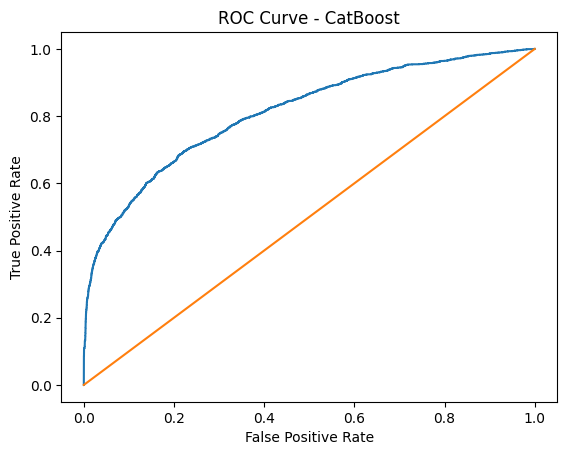

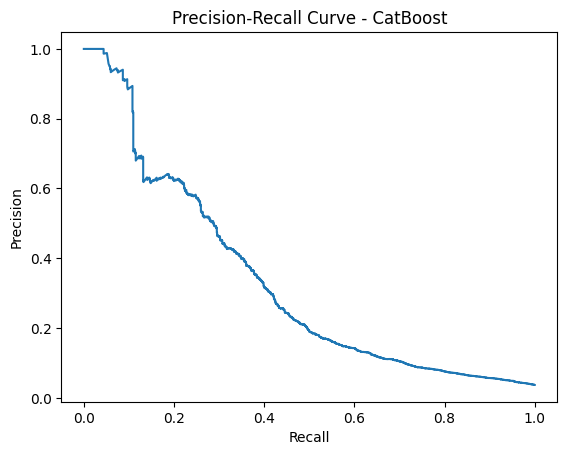

In [9]:
# Cell 6 — Prediksi probabilitas + evaluasi (ROC-AUC, PR-AUC, F1@0.5) + ROC/PR plot

from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve,
    f1_score, confusion_matrix, classification_report
)

proba_cb = catboost_vanilla.predict_proba(X_test)[:, 1]
print("Proba min/mean/max:", float(np.min(proba_cb)), float(np.mean(proba_cb)), float(np.max(proba_cb)))

roc_auc = roc_auc_score(y_test, proba_cb)
pr_auc = average_precision_score(y_test, proba_cb)

print("\nCatBoost (vanilla) ROC-AUC:", round(roc_auc, 4))
print("CatBoost (vanilla) PR-AUC :", round(pr_auc, 4))

y_pred_05 = (proba_cb >= 0.5).astype(int)
print("\nF1@0.5:", round(f1_score(y_test, y_pred_05), 4))
print("Confusion Matrix @0.5:\n", confusion_matrix(y_test, y_pred_05))
print("\nReport @0.5:\n", classification_report(y_test, y_pred_05, digits=4))

# ROC curve
fpr, tpr, _ = roc_curve(y_test, proba_cb)
plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1])
plt.title("ROC Curve - CatBoost")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

# PR curve
prec, rec, _ = precision_recall_curve(y_test, proba_cb)
plt.figure()
plt.plot(rec, prec)
plt.title("Precision-Recall Curve - CatBoost")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

<h3>Cell 7 - Threshold Tuning (Best F1)</h3>
<p>
Cell ini melakukan pencarian threshold terbaik berdasarkan kurva Precision-Recall untuk memaksimalkan F1 score.
Ini bukan untuk “mengubah” metrik utama (ROC/PR-AUC tetap prioritas), tetapi untuk memberikan insight operasional:
threshold mana yang lebih tepat jika model dipakai untuk seleksi calon repeat (misalnya untuk follow-up marketing).
</p>
<p>
Hasil tuning umumnya menghasilkan threshold yang sedikit berbeda dari 0.5, dan membantu menunjukkan trade-off precision vs recall secara lebih eksplisit di laporan.
</p>

In [10]:
# Cell 7 — Threshold tuning cepat (best F1 dari PR curve)

prec, rec, thr = precision_recall_curve(y_test, proba_cb)
f1s = (2 * prec * rec) / (prec + rec + 1e-12)

best_idx = int(np.nanargmax(f1s))
best_thr = float(thr[best_idx-1]) if best_idx > 0 and (best_idx-1) < len(thr) else 0.5

y_pred_best = (proba_cb >= best_thr).astype(int)

print("Best-F1 threshold:", round(best_thr, 4))
print("F1(best):", round(f1_score(y_test, y_pred_best), 4))

Best-F1 threshold: 0.549
F1(best): 0.3752


<h3>Cell 8 - Feature Importance (CatBoost)</h3>
<p>
Cell ini mengekstrak <i>feature importance</i> dari CatBoost dan menampilkan fitur paling berpengaruh.
Bagian ini sangat berguna untuk laporan karena CatBoost dapat menunjukkan fitur mana yang paling membantu membedakan repeat vs non-repeat, misalnya:
</p>
<ul>
  <li>Demografi: <code>umur</code>, <code>gender</code>, <code>pekerjaan</code></li>
  <li>Produk: <code>kode motor</code>, <code>type series</code>, <code>tahun rakit</code></li>
  <li>Kemampuan bayar: <code>cicilan</code>, <code>dp aktual</code>, <code>otr</code></li>
  <li>Lokasi & channel: <code>kelurahan</code>, <code>kecamatan</code>, <code>wilayah</code>, <code>kode dealer</code></li>
  <li>Waktu: <code>mohon_year</code>, <code>mohon_month</code></li>
</ul>
<p>
Interpretasi utama: feature importance bersifat indikatif (korelasi), tetapi sangat membantu untuk menjelaskan faktor-faktor yang berkaitan dengan repeat order.
</p>

In [11]:
# Cell 8 — Feature importance (CatBoost)

fi = catboost_vanilla.get_feature_importance()
fi_df = pd.DataFrame({"feature": X_train.columns, "importance": fi}).sort_values("importance", ascending=False)

print("Top 30 Feature Importance (CatBoost):")
display(fi_df.head(30))

Top 30 Feature Importance (CatBoost):


,feature,importance
10,umur,10.697819
19,kode motor,7.786011
9,pekerjaan,7.614636
24,mohon_year,5.998077
21,tahun rakit,5.933234
7,gender,5.788746
0,kelurahan,5.719959
12,cicilan,5.020308
2,kode pos,3.989461
4,kode dealer,3.929161
